# STA4020 Part 1 · 次月收益模型比较

**验证选中 50% 面板岭回归 + 50% 深度 3 的梯度提升树。** 使用 2011-01 至 2014-11 的 47 个验证月，先锁模型配方，再走完固定 50 支的 116 个样本外月。

| 固定池 OOS | 原 IC + Fama–MacBeth 岭回归 | 验证选中的混合模型 |
|---|---:|---:|
| 月收益 RMSE | 15.826% | **15.813%** |
| 平均 Rank IC | 0.1463 | **0.1494** |

MSE 下降 **0.16%**，6 个月时间块配对 95% 区间 **−0.06% 至 +0.40%**。这次 ML 提供了小幅改善，区间跨零。原模型仍是有竞争力的基准。

固定使用之前锁定的 50 支，比较各模型预测下一月简单总收益率的准确性。

## 1. 先定评价标准

| 阶段 | 时段与用途 |
|---|---|
| 滚动训练 | 每次使用最近 72 个预测标签已经实现的月份。标签的实际终点早于当期信号日。 |
| 模型验证 | **2011-01 至 2014-11** 的实现收益。在当时可评分的宽截面上逐月预测。用月均 RMSE 选模型，股票先在月内等权，各月再等权。 |
| 最终测试 | **2015-01 至 2024-08**，共 116 个月。固定模型配方，滚动更新参数，在预先锁定的 50 支股票上测试。 |

方法参考目录里的 Pedersen《Machine Learning in Asset Pricing》第 12–14 页和第 23–28 页，采用按时间顺序的训练、验证、测试，以及浅层梯度提升树。原先的 50 支于 2014-12-30 锁定，首次模拟建仓日是 2014-12-31。每期信号于月末倒数第二个交易日收盘后生成。

In [1]:
# Install the notebook dependencies from the project requirements.txt.
from pathlib import Path

import h5py
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits

PROJECT = Path(".") if Path("notebooks/Part1_Return_Model.ipynb").is_file() else Path("..")
DATA = PROJECT / "data"
OUTPUT = PROJECT / "part1_output"
FIRST_VALIDATION_TARGET = pd.Period("2011-01", freq="M")
FIRST_OOS_TARGET = pd.Period("2015-01", freq="M")
TRAIN_MONTHS = 72
RISK_MONTHS = 36
POOL_SIZE = 50
MIN_FACTOR_PAIRS = 100
MIN_IC_MONTHS = 48
RIDGE_PENALTY = 0.10  # Same penalty as the previous version
PANEL_PENALTY = 0.50
FF5_PREMIUM_SHRINK = 0.50
FDR_Q = 0.10
MAX_EXTRA_FACTORS = 5
BLOCK_MONTHS = 6
BOOTSTRAPS = 1999
SEED = 4020
TREE_THREADS = 2

CORE_FACTORS = [
    "log_size", "log_amount_21d", "volatility_63d",
    "momentum_8w", "momentum_12_1m", "return_month_to_signal",
]
LEGACY_FACTORS = [
    "log_size", "log_amount_21d", "return_5d", "volatility_63d", "momentum_8w",
    "volatility_12w", "momentum_12_1m", "lagged_month_return", "return_month_to_signal",
    "pc1_market_beta", "pca_residual_volatility",
]
LEGACY = "IC + FM ridge"
PANEL = "Pooled panel ridge"
TREE2 = "Boosting depth 2"
TREE3 = "Boosting depth 3"
BLEND = "Ridge + depth-3 blend"
HIST = "Historical stock mean"
FF5 = "FF5 risk premia"
BASE = "Common level only"
CANDIDATES = [LEGACY, PANEL, TREE2, TREE3, BLEND]
ALL_MODELS = CANDIDATES + [BASE, HIST, FF5]

plt.rcParams.update({
    "figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.alpha": 0.22, "font.size": 10,
})

## 2. 数据与锁池核验

用 monthly_returns.pkl 作实现收益标签，price.h5 和 daily_amount.pkl 构造日、周信号，mcap.pkl 提供上月末市值。信号日资格根据 BLACKLIST.pkl 和 UNTRADABLE.pkl 判断。FF5.csv 和 risk_free.csv 用于原有风险溢价基准。最新可比收益月份为 2024-08。

In [2]:
def month_index(frame):
    frame = frame.copy()
    frame.index = pd.DatetimeIndex(frame.index).to_period("M")
    frame = frame.sort_index()
    assert frame.index.is_unique and frame.columns.is_unique
    return frame


def month_end(period):
    return period.end_time.normalize()


raw_returns = month_index(pd.read_pickle(DATA / "monthly_returns.pkl"))
market_cap = month_index(pd.read_pickle(DATA / "mcap.pkl"))
first_formation = FIRST_OOS_TARGET - 1
first_validation_formation = FIRST_VALIDATION_TARGET - 1
first_tree_formation = first_validation_formation.asfreq('Q').asfreq('M', how='start')
first_feature_month = first_tree_formation - (TRAIN_MONTHS + 1)
last_target = raw_returns.index.max()
formation_months = pd.period_range(first_feature_month, last_target - 1, freq="M")
oos_months = formation_months[formation_months >= first_formation]
assert len(oos_months) >= 60
assert last_target >= FIRST_OOS_TARGET + 59
assert raw_returns.index.equals(pd.period_range(raw_returns.index[0], last_target, freq="M"))

with h5py.File(DATA / "price.h5", "r") as price_file:
    store = price_file["price"]
    trading_days = pd.DatetimeIndex(store["axis1"][:])
    price_columns = pd.Index(store["axis0"].asstr()[:], name="Asset")
    assert price_columns.equals(pd.Index(store["block0_items"].asstr()[:]))
    assert trading_days.is_unique and trading_days.is_monotonic_increasing
    start = trading_days.searchsorted((first_feature_month - 5).start_time)
    finish = trading_days.searchsorted(last_target.end_time, side="right")
    prices = pd.DataFrame(
        store["block0_values"][start:finish], index=trading_days[start:finish],
        columns=price_columns,
    )

assets = prices.columns.intersection(raw_returns.columns).sort_values()
assets = assets[assets.str.fullmatch(r"\d{6}\.(SZ|SH)")]
prices = prices.reindex(columns=assets).where(lambda values: values.gt(0))
returns = raw_returns.reindex(columns=assets).replace([np.inf, -np.inf], np.nan)
market_cap = market_cap.reindex(columns=assets)
assert (returns.stack() >= -1).all()

exchange_month = pd.Series(prices.index, index=prices.index).groupby(prices.index.to_period("M"))
last_close = exchange_month.last()
signal_close = exchange_month.nth(-2)
signal_close.index = signal_close.index.to_period("M")
assert (signal_close.reindex(formation_months) < last_close.reindex(formation_months)).all()

# Cross-check close-to-close return construction on all overlapping quotes.
end_prices = prices.loc[last_close.to_numpy()].set_axis(last_close.index)
implied_monthly = end_prices.pct_change(fill_method=None)
price_difference = (implied_monthly - returns.reindex(implied_monthly.index)).abs().stack()
assert price_difference.size > 100_000
display(pd.Series({
    "Shanghai / Shenzhen symbols in raw data": len(assets),
    "Overlapping price/return observations": price_difference.size,
    "Share matching to 1 bp": price_difference.le(0.0001).mean(),
    "First OOS target month": str(FIRST_OOS_TARGET),
    "Last OOS target month": str(last_target),
    "OOS target months": len(oos_months),
}, name="Source and calendar checks").to_frame())

,Source and calendar checks
Shanghai / Shenzhen symbols in raw data,5377
Overlapping price/return observations,645407
Share matching to 1 bp,1.0
First OOS target month,2015-01
Last OOS target month,2024-08
OOS target months,116


In [3]:
def restrictions_on_days(filename, days):
    records = pd.read_pickle(DATA / filename).index
    dates = records.get_level_values("date")
    selected = records[dates.isin(days)]
    return {
        pd.Timestamp(date): pd.Index(rows.index.get_level_values("asset").unique())
        for date, rows in selected.to_frame(index=True).groupby(level="date", sort=False)
    }


def load_daily_amount(days, asset_columns):
    amount = pd.read_pickle(DATA / "daily_amount.pkl")["total_turnover"]
    date_level = amount.index.levels[1]
    keep = date_level.isin(days)[amount.index.codes[1]]
    wide = amount.loc[keep].unstack("order_book_id")
    wide.columns = (
        wide.columns.str.replace(".XSHE", ".SZ", regex=False)
        .str.replace(".XSHG", ".SH", regex=False)
    )
    assert wide.index.is_unique and wide.columns.is_unique
    return wide.reindex(index=days, columns=asset_columns).astype("float32")


audit_days = pd.Index(signal_close.reindex(formation_months)).union(
    pd.Index(last_close.reindex(oos_months))
)
blacklist = restrictions_on_days("BLACKLIST.pkl", audit_days)
untradable = restrictions_on_days("UNTRADABLE.pkl", audit_days)
daily_amount = load_daily_amount(prices.index, assets)
assert daily_amount.notna().sum().sum() > 100_000

daily_returns = prices.pct_change(fill_method=None)
week_end_prices = (
    prices.loc[pd.Series(prices.index).groupby(prices.index.to_period("W-FRI")).last().to_numpy()]
    .set_axis(pd.Index(prices.index.to_period("W-FRI").unique().end_time.normalize()))
)
weekly_returns = week_end_prices.pct_change(fill_method=None)

ff5_factors = month_index(pd.read_csv(DATA / "FF5.csv", index_col="date", parse_dates=True))
daily_rf = pd.read_csv(DATA / "risk_free.csv", index_col="date", parse_dates=True)["RF"]
assert daily_rf.index.is_unique
required_rf = daily_rf.reindex(trading_days)
required_rf = required_rf.loc[(first_feature_month - RISK_MONTHS).start_time:last_target.end_time]
assert required_rf.notna().all()
rf_monthly = (1 + required_rf).groupby(required_rf.index.to_period("M")).prod(min_count=1) - 1


lock_signal_date = signal_close.loc[first_formation]
oos_start_close = last_close.loc[first_formation]
validation_months = formation_months[
    (formation_months >= first_validation_formation) &
    (last_close.reindex(formation_months + 1).to_numpy() < lock_signal_date)
]
assert validation_months[0] + 1 == FIRST_VALIDATION_TARGET
assert len(validation_months) >= 36
assert set(validation_months).isdisjoint(oos_months)
assert last_close.loc[validation_months[-1] + 1] < lock_signal_date < oos_start_close

locked_pool = pd.read_csv(
    OUTPUT / "P1_Candidate_Universe.csv",
    parse_dates=["Selection_Signal_Date", "Last_Selection_Training_Label_Date", "OOS_Start_Close"],
).sort_values("Selection_Rank")
fixed_universe = pd.Index(locked_pool.Asset, name="Asset")
assert len(fixed_universe) == POOL_SIZE and fixed_universe.is_unique
assert locked_pool.Selection_Signal_Date.eq(lock_signal_date).all()
assert locked_pool.OOS_Start_Close.eq(oos_start_close).all()
assert locked_pool.Last_Selection_Training_Label_Date.lt(lock_signal_date).all()
display(pd.Series({
    "Validation target months": len(validation_months),
    "Latest validation outcome": last_close.loc[validation_months[-1] + 1],
    "Original pool lock date": lock_signal_date,
    "First OOS entry close": oos_start_close,
    "Fixed tickers": len(fixed_universe),
}, name="Validation and universe audit").to_frame())

,Validation and universe audit
Validation target months,47
Latest validation outcome,2014-11-28 00:00:00
Original pool lock date,2014-12-30 00:00:00
First OOS entry close,2014-12-31 00:00:00
Fixed tickers,50


## 3. 特征和候选模型

在原 11 个特征上加入 3 个月动量、过去 12 个月波动、距 63 日高点的回撤、近期成交额变化和 Amihud 非流动性代理。每月在当时可评分的股票中做居中百分位变换。面板岭回归用中位排名填补缺失，树模型可训练缺失值分支。

**旧模型**用 Rank IC、时间块 bootstrap 和 BY 多重检验筛选额外因子。每月做一组截面岭回归，再平均 72 组系数。旧模型始终只用原 11 个特征。

**新模型**把预期收益写成共同水平加个股预测差。每个训练月的收益标签按 1% 和 99% 缩尾，再减去该月的截面均值。历史月份获得相同总权重。预测时对当期宽截面的预测差居中，加回从已成熟标签估计的共同水平。

- **面板岭回归** 一次拟合 72 个月的数据，估计一组稳定的系数。每月重估。
- **浅层梯度提升树** 两种深度 2 和 3，各 60 棵树，学习率 0.08，每叶至少 250 条记录。每个日历季度第一个信号月重估，季内每月用新特征重新预测。
- **混合预测** 以 50/50 平均面板岭回归和深度 3 的树，两者使用相同的 16 个特征。

各模型的精度用原始未缩尾实现收益计算，同时列出个股历史均值、共有水平和 FF5 对照。

In [4]:
def pca_exposures(history):
    complete = history.dropna(axis=1)
    assert complete.shape[1] >= MIN_FACTOR_PAIRS
    centered = complete.to_numpy() - complete.to_numpy().mean(axis=0)
    variances, directions = np.linalg.eigh(centered @ centered.T)
    top = directions[:, -3:][:, ::-1]
    market_direction = centered.mean(axis=1)
    direction = top[:, 0] * (1 if top[:, 0] @ market_direction >= 0 else -1)
    # Scale PC1 to the volatility of the equal-weight reference return.
    factor = direction * np.linalg.norm(market_direction)
    loading = (factor @ centered) / (factor @ factor)
    residual = centered - top @ (top.T @ centered)
    pca_features = pd.DataFrame({
        "pc1_market_beta": loading,
        "pca_residual_volatility": residual.std(axis=0, ddof=1),
    }, index=complete.columns)
    explained = variances[-3:][::-1] / variances.sum()
    return pca_features, explained


def ff5_forecast(history):
    factors = ff5_factors.reindex(history.index)
    risk_free = rf_monthly.reindex(history.index)
    assert not factors.isna().any().any() and risk_free.notna().all()
    premium = FF5_PREMIUM_SHRINK * factors.mean().to_numpy()
    rf_forecast = risk_free.iloc[-1]
    prediction = pd.Series(rf_forecast + premium[0], index=history.columns)
    complete = history.dropna(axis=1)
    design = np.column_stack([np.ones(len(factors)), factors.to_numpy()])
    excess = complete.sub(risk_free, axis=0).to_numpy()
    slopes = np.linalg.lstsq(design, excess, rcond=None)[0][1:]
    prediction.loc[complete.columns] = rf_forecast + premium @ slopes
    return prediction, len(complete.columns) / len(history.columns)


def formation_inputs(month):
    as_of = signal_close.loc[month]
    monthly_history = returns.loc[month - RISK_MONTHS:month - 1]
    recent_amount = daily_amount.loc[:as_of].tail(63)
    previous_cap = market_cap.loc[month - 1]
    blocked = blacklist.get(as_of, pd.Index([])).union(untradable.get(as_of, pd.Index([])))
    eligible = (
        prices.loc[as_of].notna()
        & previous_cap.gt(0)
        & monthly_history.tail(12).notna().all(axis=0)
        & ~assets.isin(blocked)
    )
    eligible_assets = assets[eligible]
    assert len(eligible_assets) >= max(POOL_SIZE, MIN_FACTOR_PAIRS)
    monthly_history = monthly_history.loc[:, eligible_assets]
    pca_features, explained = pca_exposures(monthly_history)
    ff5_prediction, ff5_coverage = ff5_forecast(monthly_history)

    daily = daily_returns.loc[:as_of].tail(63).loc[:, eligible_assets]
    weekly = weekly_returns.loc[:as_of].tail(12).loc[:, eligible_assets]
    recent_amount = recent_amount.loc[:, eligible_assets]
    amount_21 = recent_amount.tail(21)
    mean_amount = amount_21.mean().where(amount_21.count().ge(15))
    short_amount = recent_amount.tail(5).mean().where(recent_amount.tail(5).count().ge(4))
    long_amount = recent_amount.iloc[:-5].mean().where(recent_amount.iloc[:-5].count().ge(40))
    recent_quotes = prices.loc[:as_of].tail(63).loc[:, eligible_assets]
    high_63 = recent_quotes.max().where(recent_quotes.count().ge(50))
    daily_impact = daily.tail(21).abs().div(amount_21.where(amount_21.gt(0))).mul(1e6)
    amihud = daily_impact.mean().where(daily_impact.count().ge(15))
    prior_close = last_close.loc[month - 1]
    raw = pd.DataFrame({
        "log_size": np.log(previous_cap.loc[eligible_assets]),
        "log_amount_21d": np.log1p(mean_amount.where(mean_amount.ge(0))),
        "return_5d": (1 + daily.tail(5)).prod(min_count=5) - 1,
        "volatility_63d": daily.std().where(daily.count().ge(50)),
        "momentum_8w": (1 + weekly.tail(8)).prod(min_count=8) - 1,
        "volatility_12w": weekly.std().where(weekly.count().ge(10)),
        "momentum_12_1m": (1 + monthly_history.iloc[-12:-1]).prod(min_count=11) - 1,
        "lagged_month_return": monthly_history.iloc[-1],
        "return_month_to_signal": (
            prices.loc[as_of, eligible_assets] / prices.loc[prior_close, eligible_assets] - 1
        ),
    }).join(pca_features).assign(
        momentum_3m=(1 + monthly_history.tail(3)).prod(min_count=3) - 1,
        volatility_12m=monthly_history.tail(12).std(),
        drawdown_63d=prices.loc[as_of, eligible_assets] / high_63 - 1,
        amount_change_5d_63d=np.log1p(short_amount) - np.log1p(long_amount),
        amihud_21d=np.log1p(amihud),
    ).replace([np.inf, -np.inf], np.nan)

    # Mid-rank transformation. First rank maps just above the lowest endpoint.
    ranked = raw.rank(method="average").sub(0.5).div(raw.count())
    features = (np.sqrt(12) * (ranked - 0.5)).astype("float32")
    baseline = pd.DataFrame({
        HIST: monthly_history.mean(),
        FF5: ff5_prediction,
    })
    return features, baseline, explained, ff5_coverage

In [5]:
def block_draws(n_dates, seed=SEED):
    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(n_dates / BLOCK_MONTHS))
    starts = rng.integers(n_dates, size=(BOOTSTRAPS, n_blocks, 1))
    indices = (starts + np.arange(BLOCK_MONTHS)) % n_dates
    return indices.reshape(BOOTSTRAPS, -1)[:, :n_dates]


def by_adjust(p_values):
    valid = p_values.dropna().sort_values()
    m = len(valid)
    ranks = np.arange(1, m + 1)
    scaled = valid.to_numpy() * m * np.sum(1 / ranks) / ranks
    adjusted = np.minimum.accumulate(scaled[::-1])[::-1].clip(0, 1)
    return pd.Series(adjusted, index=valid.index).reindex(p_values.index)


def screen_factors(ic_history):
    means = ic_history.mean()
    centered = ic_history.sub(means).to_numpy()
    with np.errstate(invalid="ignore", divide="ignore"):
        samples = centered[block_draws(len(ic_history))]
        sampled_means = np.nansum(samples, axis=1) / np.isfinite(samples).sum(axis=1)
    valid_draws = np.isfinite(sampled_means).sum(axis=0)
    extreme = (np.abs(sampled_means) >= means.abs().to_numpy()).sum(axis=0)
    p_values = pd.Series((extreme + 1) / (valid_draws + 1), index=means.index)
    p_values = p_values.where(ic_history.count().ge(MIN_IC_MONTHS))
    summary = pd.DataFrame({
        "mean_rank_ic": means,
        "months": ic_history.count(),
        "p_value": p_values,
        "q_value": by_adjust(p_values),
    })
    significant_extras = summary.loc[
        summary.q_value.le(FDR_Q) & ~summary.index.isin(CORE_FACTORS)
    ].sort_values("q_value", kind="stable")
    selected = CORE_FACTORS + list(significant_extras.head(MAX_EXTRA_FACTORS).index)
    return selected, summary

In [6]:
def rank_ic(signal, target):
    measured = signal.notna() & target.notna()
    signal, target = signal.loc[measured], target.loc[measured]
    if len(signal) < MIN_FACTOR_PAIRS or signal.nunique() < 2 or target.nunique() < 2:
        return np.nan
    return float(spearmanr(signal, target).statistic)


def training_statistics(features, target):
    valid = target.notna()
    target = target.loc[valid]
    assert len(target) >= MIN_FACTOR_PAIRS
    factor_ic = features.loc[valid, LEGACY_FACTORS].apply(rank_ic, target=target)
    design = features.loc[valid].fillna(0).to_numpy(dtype=float)
    low, high = target.quantile([0.01, 0.99])
    response = target.clip(low, high).to_numpy()
    design_mean, response_mean = design.mean(axis=0), response.mean()
    centered_design, centered_response = design - design_mean, response - response_mean
    # Cache moments so different screened subsets can reuse the same monthly sample.
    return {
        "ic": factor_ic,
        "design_mean": design_mean,
        "response_mean": response_mean,
        "gram": centered_design.T @ centered_design / len(target),
        "cross": centered_design.T @ centered_response / len(target),
        "panel_features": features.loc[valid].to_numpy(dtype="float32"),
        "panel_residual": centered_response.astype("float32"),
    }


def fama_macbeth_ridge(train_stats, factor_names, feature_columns):
    selected = feature_columns.get_indexer(factor_names)
    assert (selected >= 0).all()
    penalty = np.eye(len(selected)) * RIDGE_PENALTY
    monthly_coefficients = []
    for stats in train_stats:
        slopes = np.linalg.solve(
            stats["gram"][np.ix_(selected, selected)] + penalty, stats["cross"][selected]
        )
        intercept = stats["response_mean"] - stats["design_mean"][selected] @ slopes
        monthly_coefficients.append(np.r_[intercept, slopes])
    return np.mean(monthly_coefficients, axis=0)

## 4. 逐月拟合

训练缓存只加入已成熟的标签。树模型缓存只复用同季度第一个信号日用当时数据拟合的树。

In [7]:
feature_cache = {}
training_cache = {}
trees_by_quarter = {}


def features_at(formation):
    if formation not in feature_cache:
        feature_cache[formation] = formation_inputs(formation)
    return feature_cache[formation]


def training_months_at(formation):
    as_of = signal_close.loc[formation]
    proposed = pd.period_range(formation - TRAIN_MONTHS - 1, formation - 2, freq="M")
    assert len(proposed) == TRAIN_MONTHS and proposed.isin(formation_months).all()
    assert (last_close.loc[proposed + 1] < as_of).all()
    return proposed


def causal_training_window(formation):
    months = training_months_at(formation)
    for past in months:
        if past not in training_cache:
            features = features_at(past)[0]
            mature_returns = returns.loc[past + 1].reindex(features.index)
            training_cache[past] = training_statistics(features, mature_returns)
    return months, [training_cache[past] for past in months]


def pooled_ridge(train_statistics, features):
    mean_gram = np.mean([stats["gram"] for stats in train_statistics], axis=0)
    mean_cross = np.mean([stats["cross"] for stats in train_statistics], axis=0)
    penalty = PANEL_PENALTY * np.eye(len(mean_cross))
    slopes = np.linalg.solve(mean_gram + penalty, mean_cross)
    return features.fillna(0).to_numpy() @ slopes


def fit_boosting_trees(train_statistics):
    feature_blocks = [stats["panel_features"] for stats in train_statistics]
    targets = np.concatenate([stats["panel_residual"] for stats in train_statistics])
    design = np.concatenate(feature_blocks)
    observations_per_date = np.array([len(block) for block in feature_blocks])
    # Each month has equal total weight. The average row weight stays at 1.
    weights_per_date = len(targets) / (len(feature_blocks) * observations_per_date)
    row_weights = np.repeat(weights_per_date, observations_per_date)
    models = {}
    for name, depth in [(TREE2, 2), (TREE3, 3)]:
        tree = HistGradientBoostingRegressor(
            loss="squared_error", learning_rate=0.08, max_iter=60,
            max_depth=depth, max_leaf_nodes=2**depth, min_samples_leaf=250,
            l2_regularization=5.0, max_bins=32, early_stopping=False, random_state=SEED,
        )
        with threadpool_limits(limits=TREE_THREADS):
            tree.fit(design, targets, sample_weight=row_weights)
        models[name] = tree
    return models


def add_common_level(signal, level):
    return level + signal - signal.mean()


def predict_month(formation):
    months, history = causal_training_window(formation)
    features, reference, _, _ = features_at(formation)
    ic_history = pd.DataFrame([stats["ic"] for stats in history], index=months)
    selected, _ = screen_factors(ic_history)
    legacy_coefficients = fama_macbeth_ridge(history, selected, features.columns)
    level = np.mean([stats["response_mean"] for stats in history])

    quarter = formation.asfreq("Q")
    tree_fit_month = quarter.asfreq("M", how="start")
    assert tree_fit_month <= formation
    if quarter not in trees_by_quarter:
        _, quarter_history = causal_training_window(tree_fit_month)
        trees_by_quarter[quarter] = fit_boosting_trees(quarter_history)

    predictions = reference.copy()
    predictions[BASE] = level
    predictions[LEGACY] = (
        legacy_coefficients[0] + features[selected].fillna(0) @ legacy_coefficients[1:]
    )
    predictions[PANEL] = add_common_level(pooled_ridge(history, features), level)
    current_design = features.to_numpy()
    with threadpool_limits(limits=TREE_THREADS):
        for name, tree in trees_by_quarter[quarter].items():
            predictions[name] = add_common_level(tree.predict(current_design), level)
    predictions[BLEND] = 0.5 * (predictions[PANEL] + predictions[TREE3])

    assert np.isfinite(predictions[ALL_MODELS].to_numpy()).all()
    return predictions[ALL_MODELS]

## 5. 用 OOS 以前的数据选择模型

模型选择只看验证期的月均 RMSE。截面 RMSE 则把预测和实际收益各自按月去均值后再比较，用来判断模型区分同月股票的能力。Rank IC 衡量排序，R² 衡量相对指定基准的均方误差下降比例。

选配方的范围是原个股因子模型和四种增强模型。共有水平、个股历史均值和 FF5 单列为参照。FF5 的验证期总 RMSE 更低（12.018%），同期的截面 RMSE（9.431%）高于混合模型（9.345%），平均 Rank IC 只有 0.0126。两种指标分别反映绝对收益预测和股票之间的区分度。

In [8]:
def score_forecasts(predictions, realization):
    common = realization.notna()
    prediction = predictions.loc[common]
    actual = realization.loc[common]
    assert len(actual) >= 25
    absolute_loss = prediction.sub(actual, axis="index").pow(2).mean()
    centered_loss = (
        prediction.sub(prediction.mean()).sub(actual.sub(actual.mean()), axis="index")
        .pow(2).mean()
    )
    ic = pd.Series({
        name: float(spearmanr(forecast, actual).statistic)
        if forecast.nunique() > 1 and actual.nunique() > 1 else np.nan
        for name, forecast in prediction.items()
    })
    return pd.DataFrame({
        "MSE": absolute_loss, "Centered MSE": centered_loss, "Rank IC": ic,
        "Stocks": len(actual),
    })


def summarize_scores(monthly_scores):
    summary = monthly_scores.groupby(level="Model").mean().reindex(ALL_MODELS)
    return pd.DataFrame({
        "Monthly RMSE": np.sqrt(summary["MSE"]),
        "Cross-sectional RMSE": np.sqrt(summary["Centered MSE"]),
        "Mean Rank IC": summary["Rank IC"],
        "R² vs common level": 1 - summary["MSE"] / summary.loc[BASE, "MSE"],
        "R² vs original FM": 1 - summary["MSE"] / summary.loc[LEGACY, "MSE"],
    })


def show_metrics(frame):
    return frame.style.format({
        "Monthly RMSE": "{:.3%}", "Cross-sectional RMSE": "{:.3%}",
        "Mean Rank IC": "{:+.4f}", "R² vs common level": "{:+.2%}",
        "R² vs original FM": "{:+.2%}",
    }, na_rep="—")


validation_records = {}
for formation in validation_months:
    forecasts = predict_month(formation)
    realized = returns.loc[formation + 1].reindex(forecasts.index)
    validation_records[month_end(formation + 1)] = score_forecasts(forecasts, realized)
validation_scores = pd.concat(validation_records, names=["Target_Date", "Model"])
validation_summary = summarize_scores(validation_scores)
selected_model = validation_summary.loc[CANDIDATES, "Monthly RMSE"].idxmin()
assert max(validation_scores.index.get_level_values("Target_Date").to_period("M")) < first_formation
assert max(last_close.loc[training_month + 1] for training_month in training_cache) < lock_signal_date

display(show_metrics(validation_summary.sort_values("Monthly RMSE")))
print(f"Recipe frozen before OOS: {selected_model}")

,Monthly RMSE,Cross-sectional RMSE,Mean Rank IC,R² vs common level,R² vs original FM
Model,,,,,
FF5 risk premia,12.018%,9.431%,+0.0126,+1.70%,+1.25%
Ridge + depth-3 blend,12.087%,9.345%,+0.1365,+0.57%,+0.12%
Boosting depth 2,12.088%,9.346%,+0.1373,+0.56%,+0.11%
Boosting depth 3,12.088%,9.347%,+0.1364,+0.56%,+0.11%
Pooled panel ridge,12.092%,9.352%,+0.1284,+0.49%,+0.04%
IC + FM ridge,12.094%,9.355%,+0.1286,+0.45%,+0.00%
Common level only,12.122%,9.390%,—,+0.00%,-0.46%
Historical stock mean,12.284%,9.683%,-0.0458,-2.70%,-3.16%


Recipe frozen before OOS: Ridge + depth-3 blend


## 6. 固定池的样本外预测

每月在固定池内比较各模型共同可评分且有实际收益的股票。另在全体可评分股票上重复对比。输出使用上一节锁定的模型配方。固定池里某股票当天缺少有效信号时，导出共同水平作为回退，精度对比只用有信号的共同样本。

In [9]:
fixed_records = {}
broad_records = {}
export_rows = {}
legacy_rows = {}
coverage_rows = {}
for formation in oos_months:
    forecasts = predict_month(formation)
    target_month = formation + 1
    target_date = month_end(target_month)
    realized = returns.loc[target_month]
    broad_records[target_date] = score_forecasts(forecasts, realized.reindex(forecasts.index))

    active = fixed_universe[fixed_universe.isin(forecasts.index)]
    fixed_records[target_date] = score_forecasts(forecasts.loc[active], realized.loc[active])
    common_level = forecasts[BASE].iloc[0]
    export_rows[month_end(formation)] = forecasts[selected_model].reindex(fixed_universe).fillna(common_level)
    legacy_rows[month_end(formation)] = forecasts[LEGACY].reindex(fixed_universe)
    coverage_rows[target_date] = len(active)

fixed_scores = pd.concat(fixed_records, names=["Target_Date", "Model"])
broad_scores = pd.concat(broad_records, names=["Target_Date", "Model"])
fixed_summary = summarize_scores(fixed_scores)
broad_summary = summarize_scores(broad_scores)

legacy_predictions = pd.DataFrame(legacy_rows).T
np.testing.assert_allclose(
    legacy_predictions.iloc[0].reindex(fixed_universe),
    locked_pool.Initial_Expected_Return, atol=1e-12,
)

print("Frozen 50 stocks, common valid rows")
display(show_metrics(fixed_summary))
print("Broad A-share cross-section, common valid rows")
display(show_metrics(broad_summary))
display(pd.Series({
    "OOS months": len(coverage_rows),
    "Average fixed members with a fresh signal": np.mean(list(coverage_rows.values())),
    "Stock-months using common-level fallback in export": len(oos_months) * POOL_SIZE - sum(coverage_rows.values()),
}, name="Prediction coverage").to_frame())

Frozen 50 stocks, common valid rows


,Monthly RMSE,Cross-sectional RMSE,Mean Rank IC,R² vs common level,R² vs original FM
Model,,,,,
IC + FM ridge,15.826%,12.183%,+0.1463,+0.54%,+0.00%
Pooled panel ridge,15.834%,12.189%,+0.1442,+0.44%,-0.10%
Boosting depth 2,15.805%,12.175%,+0.1503,+0.80%,+0.26%
Boosting depth 3,15.801%,12.172%,+0.1477,+0.85%,+0.31%
Ridge + depth-3 blend,15.813%,12.175%,+0.1494,+0.69%,+0.16%
Common level only,15.868%,12.229%,—,+0.00%,-0.54%
Historical stock mean,16.139%,12.376%,-0.0513,-3.44%,-3.99%
FF5 risk premia,15.927%,12.280%,-0.0093,-0.74%,-1.28%


Broad A-share cross-section, common valid rows


,Monthly RMSE,Cross-sectional RMSE,Mean Rank IC,R² vs common level,R² vs original FM
Model,,,,,
IC + FM ridge,13.935%,11.397%,+0.1050,+0.25%,+0.00%
Pooled panel ridge,13.935%,11.397%,+0.0995,+0.25%,-0.00%
Boosting depth 2,13.925%,11.384%,+0.1087,+0.41%,+0.15%
Boosting depth 3,13.922%,11.381%,+0.1083,+0.44%,+0.19%
Ridge + depth-3 blend,13.926%,11.385%,+0.1098,+0.39%,+0.14%
Common level only,13.953%,11.419%,—,+0.00%,-0.25%
Historical stock mean,14.314%,11.704%,-0.0378,-5.24%,-5.50%
FF5 risk premia,13.997%,11.454%,+0.0074,-0.63%,-0.89%


,Prediction coverage
OOS months,116.000000
Average fixed members with a fresh signal,45.931034
Stock-months using common-level fallback in export,472.000000


,Selected model on frozen pool
Reduction in MSE vs original,+0.16%
95% paired interval low,-0.06%
95% paired interval high,+0.40%


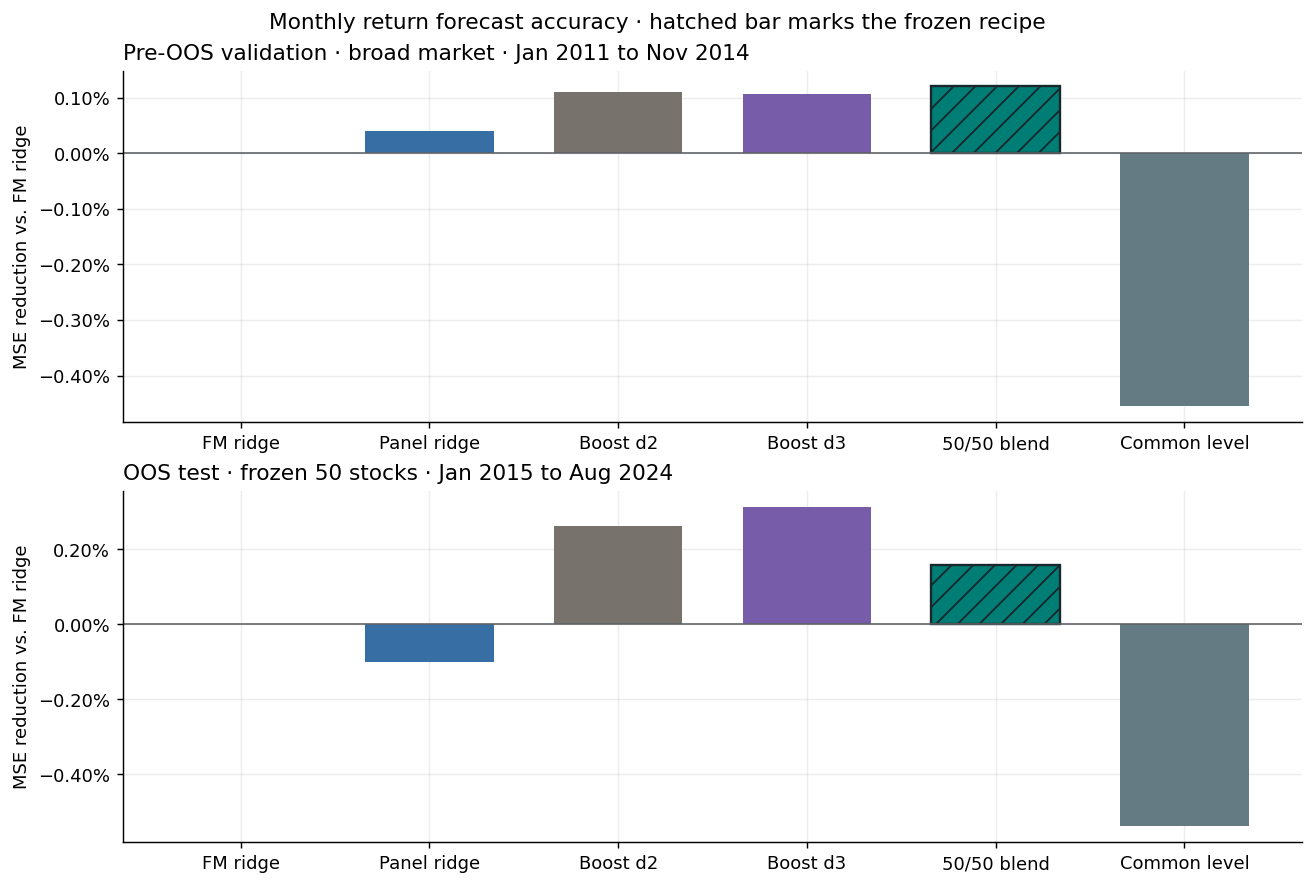

In [10]:
fixed_loss = fixed_scores["MSE"].unstack("Model")
paired_loss = (fixed_loss[LEGACY] - fixed_loss[selected_model]) / fixed_loss[LEGACY].mean()
resampled_mean = paired_loss.to_numpy()[block_draws(len(paired_loss), seed=SEED + 1)].mean(axis=1)
lower, upper = np.quantile(resampled_mean, [0.025, 0.975])
display(pd.Series({
    "Reduction in MSE vs original": paired_loss.mean(),
    "95% paired interval low": lower,
    "95% paired interval high": upper,
}, name="Selected model on frozen pool").to_frame().style.format("{:+.2%}"))

colors = {
    LEGACY: "#B45C25", PANEL: "#376EA3", TREE2: "#77726C",
    TREE3: "#765CA9", BLEND: "#007E75", BASE: "#647B84",
}
short_names = ["FM ridge", "Panel ridge", "Boost d2", "Boost d3", "50/50 blend", "Common level"]
chart_order = CANDIDATES + [BASE]
fig, axes = plt.subplots(2, 1, figsize=(10, 6.7), layout="constrained")
x = np.arange(len(chart_order))
for axis, metrics, title in [
    (axes[0], validation_summary, "Pre-OOS validation · broad market · Jan 2011 to Nov 2014"),
    (axes[1], fixed_summary, "OOS test · frozen 50 stocks · Jan 2015 to Aug 2024"),
]:
    mse_improvement = metrics.loc[chart_order, "R² vs original FM"]
    bars = axis.bar(x, mse_improvement, color=[colors[name] for name in chart_order], width=0.68)
    for name, rectangle in zip(chart_order, bars):
        if name == selected_model:
            rectangle.set_edgecolor("#17272B")
            rectangle.set_linewidth(1.3)
            rectangle.set_hatch("//")
    axis.axhline(0, color="#5F6266", lw=0.9)
    axis.set_xticks(x, short_names)
    axis.set_ylabel("MSE reduction vs. FM ridge")
    axis.yaxis.set_major_formatter(PercentFormatter(1.0))
    axis.set_title(title, loc="left")
fig.suptitle("Monthly return forecast accuracy · hatched bar marks the frozen recipe")
plt.show()

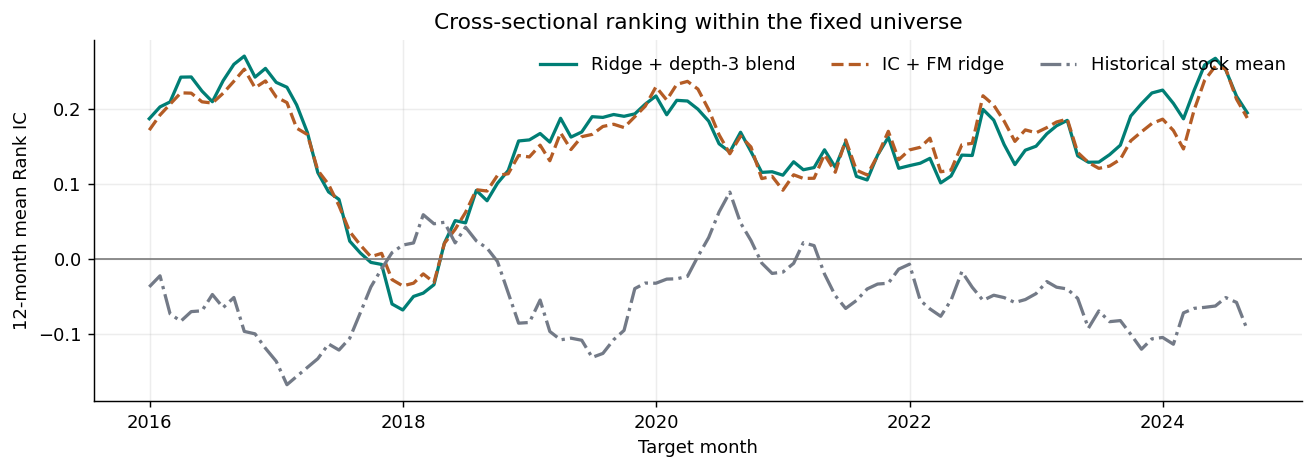

In [11]:
fig, axis = plt.subplots(figsize=(10, 3.5), layout="constrained")
monthly_ic = fixed_scores["Rank IC"].unstack("Model")
comparison_names = list(dict.fromkeys([selected_model, LEGACY, HIST]))
for name, style in zip(comparison_names, ["-", "--", "-."]):
    axis.plot(monthly_ic[name].rolling(12).mean(), label=name,
              color=colors.get(name, "#737A87"), linestyle=style, lw=1.8)
axis.axhline(0, color="#777777", lw=0.9)
axis.xaxis.set_major_locator(mdates.YearLocator(2))
axis.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axis.set(title="Cross-sectional ranking within the fixed universe",
         ylabel="12-month mean Rank IC", xlabel="Target month")
axis.legend(frameon=False, loc="upper right", ncols=3)
plt.show()

### 结果怎么读

- 在 47 个前置验证月中，混合模型在五个候选模型里 RMSE 最低，为 12.087%。原模型为 12.094%。验证期的几种树模型预测误差非常接近。
- 固定池样本外的深度 3 树单独使用时达到 15.801% RMSE。这个数字是测试期诊断。交接文件由前置验证选出的混合模型生成。
- 在宽截面的样本外对照中，混合模型 RMSE 为 13.926%，原模型为 13.935%，Rank IC 分别为 0.1098 和 0.1050。两个测试对象都只显示小幅改善。
- 两种模型都比个股历史均值更能排序。相对于只有一个共同水平的预测，混合模型在固定池的 MSE 改善为 0.69%。预测改善幅度较小。
- 每月平均 45.93 支有可用信号，共有 472 个股票月在导出时使用共同水平回退。表中的预测对比以各模型共同有信号且有实际收益的样本为准。含回退值核对全部 5,800 个导出预测时，混合模型 RMSE 为 16.234%，原导出文件为 16.245%。

## 7. 导出预测

输出 part1_output/P1_Validated_Expected_Returns.csv。Date 是调仓月的日历月末，每格是该股票下个月的简单总收益率，小数单位。列顺序与既有固定名单相同。和既有实际收益表对接时，预测日期加一个月匹配实现日期。

In [12]:
optimized_forecasts = pd.DataFrame(export_rows).T.reindex(columns=fixed_universe)
optimized_forecasts.index.name = "Date"
actual = pd.read_csv(OUTPUT / "Actual_Returns.csv", index_col="Date", parse_dates=True)
assert optimized_forecasts.columns.equals(fixed_universe)
assert list(actual.columns) == list(fixed_universe)
assert (optimized_forecasts.index.to_period("M") + 1).equals(actual.index.to_period("M"))
assert optimized_forecasts.shape == (len(oos_months), POOL_SIZE)
assert np.isfinite(optimized_forecasts.to_numpy()).all()

output_path = OUTPUT / "P1_Validated_Expected_Returns.csv"
optimized_forecasts.to_csv(output_path)
print(f"{selected_model} → {output_path} ({len(optimized_forecasts)} months × {POOL_SIZE} tickers)")
display(optimized_forecasts.iloc[:3, :6].style.format("{:+.2%}"))

Ridge + depth-3 blend → part1_output/P1_Validated_Expected_Returns.csv (116 months × 50 tickers)


Asset,300281.SZ,300069.SZ,600768.SH,600137.SH,300277.SZ,300354.SZ
Date,,,,,,
2014-12-31 00:00:00,+4.53%,+4.75%,+4.94%,+4.63%,+4.81%,+4.68%
2015-01-31 00:00:00,+3.80%,+4.01%,+1.64%,+3.86%,+3.72%,+2.10%
2015-02-28 00:00:00,+2.43%,+3.38%,+3.40%,+3.76%,+3.44%,+1.35%
